# Demo

This is a A **demonstration** script for the ECLYPSE network simulator extension.

It sets up an IoT and Core Network topology, defines application traffic flows, and measures the end-to-end packet delays to demonstrate the emergence of network bottlenecks and routing performance under specific traffic loads.

**Network Topology**

The infrastructure is composed of the following nodes and connections:
Access Links

- Sensor → Gateway (100 Mbps, 1 km)
- SensorX → Gateway (200 Mbps, 1 km)
- SensorY → R1 (200 Mbps, 1 km)

**Core Network Links**

- Gateway → R1 (40 Mbps, 5 km)
- Gateway → R2 (50 Mbps, 5 km)
- R1 → R2 (50 Mbps, 2 km)
- R1 → R3 (50 Mbps, 10 km)
- R2 → R3 (50 Mbps, 10 km)

**Bottleneck Link**
- R3 → Cloud (10 Mbps, 50 km)


**Application & Traffic Flows**

A `NetworkApplication` called VideoApp simulates a video streaming scenario. It maps components to the infrastructure using a StaticStrategy:

- **Sensor1** (placed on Sensor) → Cloud1 (placed on Cloud)

- **SensorX1** (placed on SensorX) → Cloud1 (placed on Cloud)

- **SensorY1** (placed on SensorY) → Cloud1 (placed on Cloud)

Each flow generates traffic towards the Cloud component with a packet size of 1500 bytes and an average of 10 packets per step, highlighting how concurrent streams converge into the 10 Mbps bottleneck link (R3 → Cloud).
Simulation Configuration

The simulation runs with the following parameters:

- **Duration**: 101 steps (max_steps=101), with each step occurring every 500 ms of real time. Each step covers 0.5 ms of simulated time, so the run simulates about 50 ms: enough for the packets of all three flows to reach the bottleneck, since a packet is forwarded only after it has arrived at its router.
- **Execution Events**: Implements PacketGenerationEvent and RoutingEvent (step duration: 0.5 ms).
- **Metrics & Output**: Captures data via RoutingMetric and saves the results in JSON format inside the ~/eclypse-sim/demo/bottleneck directory using a Pandas backend.

In [1]:
from eclypse.simulation.config import SimulationConfig
import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [2]:
from eclypse.network import (
                            Network,
                            NetworkApplication,
                            PacketGenerationEvent,
                            RoutingEvent,
                            RoutingMetric
                        )

import shutil

from eclypse.simulation import Simulation
from eclypse.utils.defaults import get_default_sim_path
from eclypse.placement.strategies import StaticStrategy

print("1. Setting up Infrastructure...")
infra = Network("IoT_Network")

# Add real resources to the hosts
infra.add_host("Sensor", processing_time=0.0001, cpu=2, ram=4)
infra.add_host("SensorX", processing_time=0.0001, cpu=2, ram=4)
infra.add_host("SensorY", processing_time=0.0001, cpu=2, ram=4)

# The constructor of the router class put 0 on cpu and ram automcatically
infra.add_router("Gateway", processing_time=0.0001)
infra.add_router("R1", processing_time=0.0001)
infra.add_router("R2", processing_time=0.0001)
infra.add_router("R3", processing_time=0.0001)

infra.add_host("Cloud", processing_time=0.0001, cpu=16, ram=32)

# Access Link (Sensor -> Gateway): 100 Mbps, 1 km
infra.add_edge("Sensor", "Gateway", bandwidth_mbps=100, length_km=1, max_queue_size=100)
# Access Link (SensorX -> Gateway): 200 Mbps, 1 km
infra.add_edge("SensorX", "Gateway", bandwidth_mbps=200, length_km=1, max_queue_size=100)
# Access Link (SensorY -> R1): 200 Mbps, 1 km
infra.add_edge("SensorY", "R1", bandwidth_mbps=200, length_km=1, max_queue_size=100)

# Core Network Links: 50 Mbps
# 40 Mbps instead of 50: otherwise Gateway -> R1 -> R3 and Gateway -> R2 -> R3 would have
# the same routing cost, and the path chosen would depend on the shortest-path library
infra.add_edge("Gateway", "R1", bandwidth_mbps=40, length_km=5, max_queue_size=100)
infra.add_edge("Gateway", "R2", bandwidth_mbps=50, length_km=5, max_queue_size=100)
infra.add_edge("R1", "R2", bandwidth_mbps=50, length_km=2, max_queue_size=100)
infra.add_edge("R1", "R3", bandwidth_mbps=50, length_km=10, max_queue_size=100)
infra.add_edge("R2", "R3", bandwidth_mbps=50, length_km=10, max_queue_size=100)

# Bottleneck Link (R3 -> Cloud): 10 Mbps, 50 km
infra.add_edge("R3", "Cloud", bandwidth_mbps=10, length_km=50, max_queue_size=100)


print("2. Setting up Application (Video Stream)...")
app = NetworkApplication("VideoApp")

app.add_node("Sensor1", cpu=1, ram=1, gpu=0, storage=0, availability=0.0)
app.add_node("SensorX1", cpu=1, ram=1, gpu=0, storage=0, availability=0.0)
app.add_node("SensorY1", cpu=1, ram=1, gpu=0, storage=0, availability=0.0)
app.add_node("Cloud1", cpu=10, ram=8, gpu=0, storage=0, availability=0.0)

app.add_edge("Sensor1",
             "Cloud1",
             packet_size_bytes=1500,
             avg_packets_per_step=10,
             bandwidth=0,
             latency=1000
            )


app.add_edge("SensorX1",
             "Cloud1",
             packet_size_bytes=1500,
             avg_packets_per_step=10,
             bandwidth=0,
             latency=1000
            )

app.add_edge("SensorY1",
             "Cloud1",
             packet_size_bytes=1500,
             avg_packets_per_step=10,
             bandwidth=0,
             latency=1000
            )

packet_event = PacketGenerationEvent()
execution_event = RoutingEvent(step_duration_s=0.0005)
reporting_metric = RoutingMetric()

BOTTLENECK_RESULTS = get_default_sim_path() / "demo" / "bottleneck"
# ECLYPSE writes to a new timestamped folder if the path exists: start from a clean one
shutil.rmtree(BOTTLENECK_RESULTS, ignore_errors=True)

sim_config = SimulationConfig(
    seed=42,
    max_steps=101,
    step_every_ms=500,
    path=BOTTLENECK_RESULTS,
    events=[packet_event, execution_event, reporting_metric],
    include_default_metrics=False,
    report_format="json",
    report_backend="pandas",
    remote=False,
    log_level="DEBUG"
)

print("3. Initializing Simulation...")
sim = Simulation(infra, simulation_config=sim_config)

# Use Static strategy for placement
strategy = StaticStrategy({
    "Sensor1": "Sensor",
    "SensorX1": "SensorX",
    "SensorY1": "SensorY",
    "Cloud1": "Cloud"
})
sim.register(app, placement_strategy=strategy)

sim.start()
sim.wait()

1. Setting up Infrastructure...
2. Setting up Application (Video Stream)...
16:59:30.074 | INFO | VideoApp - Added flow Sensor1->Cloud1, 10 pkt/step (avg), size 1500B
16:59:30.075 | INFO | VideoApp - Added flow SensorX1->Cloud1, 10 pkt/step (avg), size 1500B
16:59:30.075 | INFO | VideoApp - Added flow SensorY1->Cloud1, 10 pkt/step (avg), size 1500B
3. Initializing Simulation...
16:59:30.354 | DEBUG | Simulation - Registered application | app=VideoApp | remote=False
16:59:30.355 | ECLYPSE | Simulation - Simulation configuration | infrastructure=IoT_Network | path=/home/davide-orsucci/eclypse-sim/demo/bottleneck | remote=False | step_every_ms=500 | max_steps=101 | seed=42 | report_format=json | report_backend=pandas | log_level=DEBUG | log_to_file=False | include_default_metrics=False
16:59:30.356 | DEBUG | Simulation - Event triggered | name=enact | triggers=1
16:59:30.355 | ECLYPSE | Simulation - Simulation started.
16:59:30.359 | ECLYPSE | PlacementManager - Placement established | ap

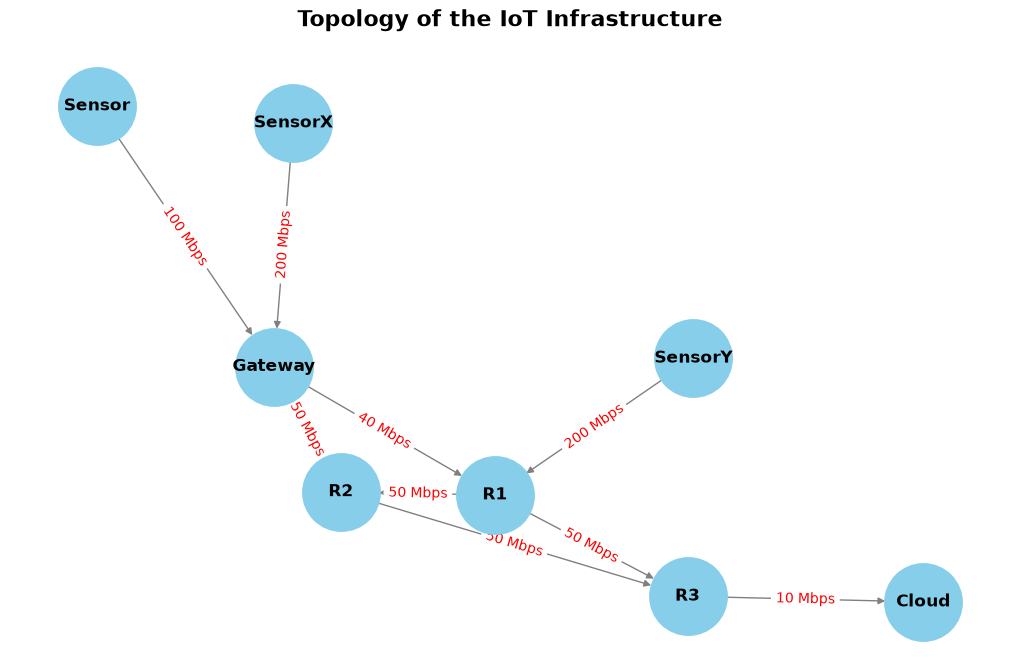

In [3]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a NetworkX graph from the infrastructure
plt.figure(figsize=(10, 6))

pos_base = nx.kamada_kawai_layout(infra)
pos = nx.spring_layout(infra, pos=pos_base, k=1.0, iterations=50, seed=42)
# Draw the network with custom styling
nx.draw(
    infra,
    pos,
    with_labels=True,
    node_color='skyblue',
    node_size=3000,
    font_size=12,
    font_weight='bold',
    edge_color='gray',
    linewidths=2
)

# print the bandwidth on the edges using the 'bandwidth_mbps' attribute
edge_labels = nx.get_edge_attributes(infra, 'bandwidth_mbps')
if edge_labels:
    # add "Mbps" to the bandwidth values for better readability
    formatted_labels = {edge: f"{bw} Mbps" for edge, bw in edge_labels.items()}
    nx.draw_networkx_edge_labels(infra, pos, edge_labels=formatted_labels, font_color='red')

plt.title("Topology of the IoT Infrastructure", fontsize=16, fontweight='bold', pad=20)
plt.axis('off')  # Hide axes for better visualization
plt.show()

In [4]:
import pandas as pd
import json
import os

json_path = f"{BOTTLENECK_RESULTS}/json/application.jsonl"
df_list = []

if not os.path.exists(json_path):
    raise FileNotFoundError(f"File {json_path} not found")

# Lecture of the JSONL file and filtering for routing metrics
with open(json_path, 'r') as file:
    for line in file:
        if line.strip():
            record = json.loads(line)
            
            # Filter using the callback_name to only include routing metrics
            if record.get("callback_name") == "traffic_routing":
                step_dict = {}
                metrics = [m for m in record.get("data", []) if len(m) == 3]
                
                # Reconstruct the original dictionary
                for app_id, col_name, val_list in metrics:
                    step_dict[col_name] = val_list
                
                # Convert to DataFrame in O(1) time if there are data
                if step_dict:
                    df_list.append(pd.DataFrame(step_dict))

if not df_list:
    raise ValueError("The JSONL file is empty or does not contain valid routing metrics.")

# Fusion of all steps into a single DataFrame
df_pivot = pd.concat(df_list, ignore_index=True)

# Rename columns to maintain compatibility with the old log names
df_pivot.rename(columns={
    'step': 'Step',
    'packet_id': 'Packet_ID',
    'hop_count': 'Hop_ID'
}, inplace=True)

# Conversion of types for safety
numeric_cols = ['arrival_at_next', 'processing_ms', 'queue_ms', 'transmission_ms', 'propagation_ms']
for col in numeric_cols:
    if col in df_pivot.columns:
        df_pivot[col] = pd.to_numeric(df_pivot[col], errors='coerce')

df_pivot['queue_length'] = pd.to_numeric(df_pivot.get('queue_length', 0)).fillna(0).astype(int)

# Secure handling of the 'dropped' field
if 'dropped' in df_pivot.columns:
    df_pivot['dropped'] = df_pivot['dropped'].fillna(False).astype(bool)
else:
    df_pivot['dropped'] = False

if 'hop' not in df_pivot.columns:
    df_pivot['hop'] = "Route N/A"

# Print of the chronological log of hops
print("\n--- Chronological Log of Hops ---")

df_log = df_pivot.sort_values('arrival_at_next').dropna(subset=['arrival_at_next'])

for _, row in df_log.iterrows():
    route_name = str(row['hop'])
    drop_alert = " ⚠️ [DROPPED]" if row['dropped'] else ""

    print(f"[Arrival: {row['arrival_at_next']:7.4f} ms] | "
          f"Step: {row['Step']:<3} | "
          f"Pkt: {row['Packet_ID']:<3} (Hop {row['Hop_ID']}) | "
          f"Route: {route_name:<15} | "
          f"Queue: {row['queue_length']:>2} pkt | "
          f"Delay Queue: {row['queue_ms']:6.4f} ms{drop_alert}")


--- Chronological Log of Hops ---
[Arrival:  0.6650 ms] | Step: 1   | Pkt: 19  (Hop 1) | Route: SensorY->R1     | Queue:  0 pkt | Delay Queue: 0.0000 ms
[Arrival:  0.6650 ms] | Step: 1   | Pkt: 13  (Hop 1) | Route: SensorX->Gateway | Queue:  0 pkt | Delay Queue: 0.0000 ms
[Arrival:  0.7250 ms] | Step: 1   | Pkt: 20  (Hop 1) | Route: SensorY->R1     | Queue:  1 pkt | Delay Queue: 0.0600 ms
[Arrival:  0.7250 ms] | Step: 1   | Pkt: 1   (Hop 1) | Route: Sensor->Gateway | Queue:  0 pkt | Delay Queue: 0.0000 ms
[Arrival:  0.7250 ms] | Step: 1   | Pkt: 14  (Hop 1) | Route: SensorX->Gateway | Queue:  1 pkt | Delay Queue: 0.0600 ms
[Arrival:  0.7850 ms] | Step: 1   | Pkt: 21  (Hop 1) | Route: SensorY->R1     | Queue:  2 pkt | Delay Queue: 0.1200 ms
[Arrival:  0.7850 ms] | Step: 1   | Pkt: 15  (Hop 1) | Route: SensorX->Gateway | Queue:  2 pkt | Delay Queue: 0.1200 ms
[Arrival:  0.8450 ms] | Step: 1   | Pkt: 2   (Hop 1) | Route: Sensor->Gateway | Queue:  1 pkt | Delay Queue: 0.1200 ms
[Arrival: 

In [5]:
import os
import json
import pandas as pd

json_path = f"{BOTTLENECK_RESULTS}/json/application.jsonl"
df_list = []

if not os.path.exists(json_path):
    raise FileNotFoundError(f"File {json_path} non trovato.")

# Lecture and extraction of routing metrics from the JSONL file
with open(json_path, 'r') as f:
    for line in f:
        if line.strip():
            log = json.loads(line)
            if log.get('callback_name') == 'traffic_routing':
                step_dict = {}
                for item in log.get('data', []):
                    if len(item) == 3:
                        step_dict[item[1]] = item[2]
                if step_dict:
                    df_list.append(pd.DataFrame(step_dict))

if not df_list:
    raise ValueError("Nessun record di routing valido trovato nel file JSONL.")

df = pd.concat(df_list, ignore_index=True)

# Redenomination of columns to maintain compatibility with the old log names
df.rename(columns={
    'packet_id': 'pkt_id',
    'hop_count': 'hop',
    'hop': 'route',
    'processing_ms': 'processing',
    'queue_ms': 'queue',
    'transmission_ms': 'transmission',
    'propagation_ms': 'propagation'
}, inplace=True)

# Analysis of the delays for a specific packet
pkt_id = 1
pkt_data = df[df['pkt_id'] == pkt_id].sort_values('hop').copy()

if pkt_data.empty:
    print(f"Nessun dato trovato per il pacchetto {pkt_id}.")
else:
    # Decomposition of the delays for the selected packet
    print(f"Decomposition of the delays for packet {pkt_id}:")
    print(pkt_data[['hop', 'route', 'processing', 'queue', 'transmission', 'propagation']])

    # Calculation of the total end-to-end delay for the selected packet
    delay_cols = ['processing', 'queue', 'transmission', 'propagation']
    e2e = pkt_data[delay_cols].sum()

    print("\n--- Total E2E delay by component (ms) ---")
    print(e2e)
    print(f"\nTotal E2E latency: {e2e.sum():.4f} ms")

Decomposition of the delays for packet 1:
     hop            route  processing  queue  transmission  propagation
0      1  Sensor->Gateway         0.1   0.00          0.12        0.005
60     2      Gateway->R2         0.1   0.48          0.24        0.025
170    3           R2->R3         0.1   0.24          0.24        0.050
276    4        R3->Cloud         0.1   9.30          1.20        0.250

--- Total E2E delay by component (ms) ---
processing       0.40
queue           10.02
transmission     1.80
propagation      0.33
dtype: float64

Total E2E latency: 12.5500 ms


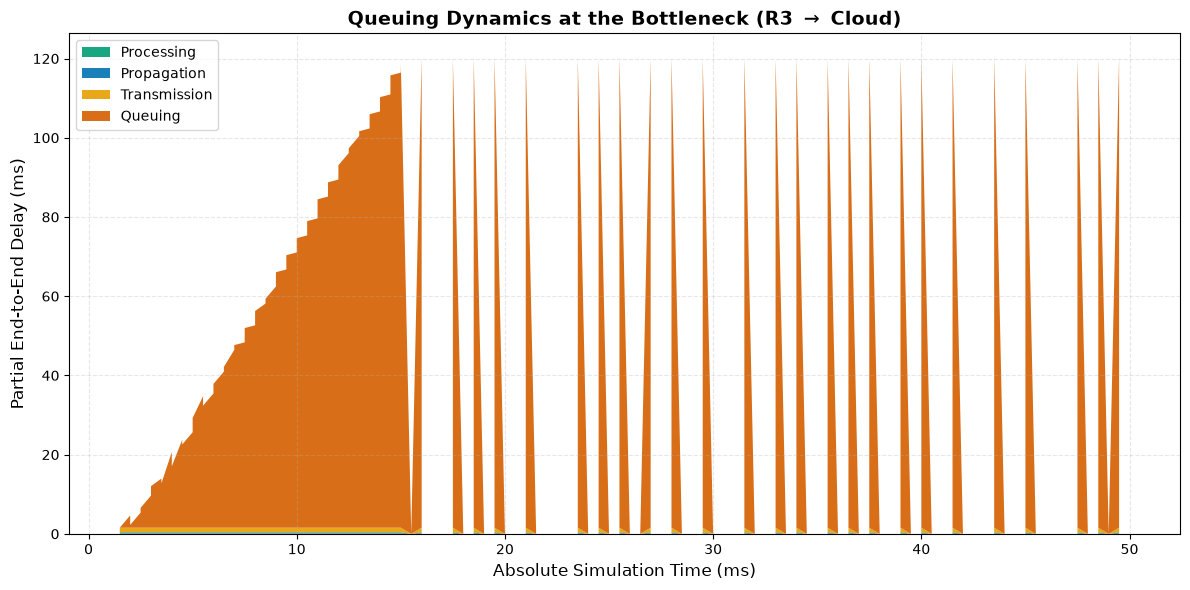

In [6]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import numpy as np
import os

def load_and_process_data(json_path: str, bottleneck_hop: str = 'R3->Cloud'):
    """
    Load logs from the JSONL file, convert SoA metrics to a DataFrame,
    and calculate the physical arrival time at the bottleneck ingress.
    """
    if not os.path.exists(json_path):
        raise FileNotFoundError(f"File {json_path} not found")

    df_list = []

    with open(json_path, 'r') as f:
        for line in f:
            if line.strip():
                log = json.loads(line)
                # Intercept the correct callback for routing metrics
                if log.get('callback_name') == 'traffic_routing':
                    step_dict = {}
                    for item in log.get('data', []):
                        if len(item) == 3:
                            step_dict[item[1]] = item[2]
                    
                    if step_dict:
                        df_list.append(pd.DataFrame(step_dict))

    if not df_list:
        raise ValueError("The JSONL file is empty or does not contain valid routing metrics.")

    # Concatenate all steps into a single DataFrame
    df = pd.concat(df_list, ignore_index=True)

    # Filter only the packets that traverse the bottleneck
    bottleneck_df = df[df['hop'] == bottleneck_hop].copy()
    
    # Ensure that the fields are numeric
    cols_to_numeric = ['arrival_at_next', 'processing_ms', 'queue_ms', 'transmission_ms', 'propagation_ms']
    for col in cols_to_numeric:
        bottleneck_df[col] = pd.to_numeric(bottleneck_df[col], errors='coerce').fillna(0)

    # Calculate the moment when the packet physically entered the router's queue
    bottleneck_df['arrival_time_ms'] = bottleneck_df['arrival_at_next'] - (
        bottleneck_df['processing_ms'] +
        bottleneck_df['queue_ms'] +
        bottleneck_df['transmission_ms'] +
        bottleneck_df['propagation_ms']
    )

    return bottleneck_df.sort_values('arrival_time_ms')


df_bottleneck = load_and_process_data(f"{BOTTLENECK_RESULTS}/json/application.jsonl")

delay_cols = ['processing_ms', 'propagation_ms', 'transmission_ms', 'queue_ms']
plot_data = df_bottleneck[delay_cols]

x = df_bottleneck['arrival_time_ms'].to_numpy(dtype=float)
y_data = [
    plot_data['processing_ms'].to_numpy(dtype=float),
    plot_data['propagation_ms'].to_numpy(dtype=float),
    plot_data['transmission_ms'].to_numpy(dtype=float),
    plot_data['queue_ms'].to_numpy(dtype=float)
]

plt.figure(figsize=(12, 6))

plt.stackplot(
    x,
    *y_data,
    labels=['Processing', 'Propagation', 'Transmission', 'Queuing'],
    alpha=0.9,
    colors=['#009E73', '#0072B2', '#E69F00', '#D55E00']
)

plt.title(r'Queuing Dynamics at the Bottleneck (R3 $\rightarrow$ Cloud)', fontsize=14, fontweight='bold')
plt.xlabel('Absolute Simulation Time (ms)', fontsize=12)
plt.ylabel('Partial End-to-End Delay (ms)', fontsize=12)
plt.legend(loc='upper left', fontsize=10, frameon=True)
plt.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# Failure recovery

This is a demonstration script for the ECLYPSE network simulator extension focusing on network resilience and fault tolerance.

It sets up an IoT and Core Network topology, defines an application traffic flow, and introduces dynamic network failures to demonstrate the emergence of alternative routing paths, packet loss, and latency spikes under fault conditions.


**Network Topology**

The infrastructure is composed of the following nodes and connections:

**Access Link**
- Sensor → Gateway (100 Mbps, 1 km)

**Core Network Links**(Mesh Topology)
- Gateway → R1 (50 Mbps, 5 km)
- Gateway → R2 (50 Mbps, 5 km)
- R1 → R2 (50 Mbps, 2 km)
- R1 → R3 (50 Mbps, 10 km)
- R2 → R3 (50 Mbps, 10 km)

**Cloud Link**
- R3 → Cloud (10 Mbps, 50 km)

Application & Traffic Flows

A `NetworkApplication` called VideoApp simulates a single video streaming scenario mapped via StaticStrategy:

- **Sensor1** (placed on Sensor) → Cloud1 (placed on Cloud)

The flow generates traffic with a packet size of 1500 bytes and an average of 2 packets per step. Given the redundant paths in the core network (via R1 and R2), the simulation evaluates how traffic is dynamically rerouted when links or nodes fail.
Simulation Configuration & Fault Injection

The simulation runs with an extended timeline to observe the effects of infrastructure failures:

- **Duration**: 101 steps (max_steps=101), with each step occurring every 500 ms.

- **Fault Injection**: Includes the FaultInjectionEvent in the simulation pipeline, which dynamically triggers network anomalies or link disruptions during execution.

- **Execution Events**: Implements PacketGenerationEvent and RoutingEvent (step duration: 0.5 ms).

- **Metrics & Outpu**t: Captures performance drops and recovery metrics via RoutingMetric, exporting results in JSON format to the ~/eclypse-sim/demo/fault_recovery directory.

In [7]:
from eclypse.simulation.config import SimulationConfig
import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [8]:
from eclypse.network import (
                            Network,
                            NetworkApplication,
                            PacketGenerationEvent,
                            RoutingEvent,
                            RoutingMetric,
                        )
from fault_injection import FaultInjectionEvent  # same folder as this notebook
from eclypse.placement.strategies import StaticStrategy
import shutil

from eclypse.simulation import Simulation
from eclypse.utils.defaults import get_default_sim_path

print("1. Setting up Infrastructure...")
infra = Network("IoT_Network")

infra.add_host("Sensor", processing_time=0.0001)
infra.add_host("Cloud", processing_time=0.0001)

infra.add_router("Gateway", processing_time=0.0001)
infra.add_router("R1", processing_time=0.0001)
infra.add_router("R2", processing_time=0.0001)
infra.add_router("R3", processing_time=0.0001)



# Access Link (Sensor -> Gateway): 100 Mbps, 1 km
infra.add_edge("Sensor", "Gateway", bandwidth_mbps=100, length_km=1, max_queue_size=100)

# Core Network Links: 50 Mbps
infra.add_edge("Gateway", "R1", bandwidth_mbps=100, length_km=5, max_queue_size=100)
infra.add_edge("Gateway", "R2", bandwidth_mbps=50, length_km=5, max_queue_size=100)
infra.add_edge("R1", "R2", bandwidth_mbps=50, length_km=2, max_queue_size=100)
infra.add_edge("R1", "R3", bandwidth_mbps=50, length_km=10, max_queue_size=100)
infra.add_edge("R2", "R3", bandwidth_mbps=50, length_km=10, max_queue_size=100)
# Bottleneck Link (R3 -> Cloud): 10 Mbps, 50 km
infra.add_edge("R3", "Cloud", bandwidth_mbps=10, length_km=50, max_queue_size=100)


print("2. Setting up Application (Video Stream)...")
app = NetworkApplication("VideoApp")

app.add_node("Sensor1", cpu=0, ram=0, gpu=0, storage=0, availability=0.0)
app.add_node("Cloud1", cpu=0, ram=0, gpu=0, storage=0, availability=0.0)


app.add_edge(
    "Sensor1", "Cloud1", packet_size_bytes=1500, avg_packets_per_step=2, bandwidth=0, latency=1000
)

packet_event = PacketGenerationEvent()
traffic_event = RoutingEvent(step_duration_s=0.0005)
traffic_metric = RoutingMetric()

FAULT_RESULTS = get_default_sim_path() / "demo" / "fault_recovery"
# ECLYPSE writes to a new timestamped folder if the path exists: start from a clean one
shutil.rmtree(FAULT_RESULTS, ignore_errors=True)

sim_config = SimulationConfig(
    seed=42,
    max_steps=101,
    step_every_ms=500,
    path=FAULT_RESULTS,
    events=[packet_event, traffic_event, traffic_metric, FaultInjectionEvent],
    include_default_metrics=False,
    report_format="json",
    report_backend="pandas",
    remote=False,
)

print("3. Initializing Simulation...")
sim = Simulation(infra, simulation_config=sim_config)

strategy = StaticStrategy({"Sensor1": "Sensor", "Cloud1": "Cloud"})
sim.register(app, placement_strategy=strategy)

sim.start()
sim.wait()

1. Setting up Infrastructure...
2. Setting up Application (Video Stream)...
17:00:22.135 | DEBUG | IoT_Network - Added Host node: Sensor
17:00:22.135 | DEBUG | IoT_Network - Added Host node: Cloud
17:00:22.135 | DEBUG | IoT_Network - Added Router node: Gateway
17:00:22.135 | DEBUG | IoT_Network - Added Router node: R1
17:00:22.135 | DEBUG | IoT_Network - Added Router node: R2
17:00:22.136 | DEBUG | IoT_Network - Added Router node: R3
17:00:22.136 | INFO | VideoApp - Added flow Sensor1->Cloud1, 2 pkt/step (avg), size 1500B
3. Initializing Simulation...
17:00:22.214 | ECLYPSE | Simulation - Simulation configuration | infrastructure=IoT_Network | path=/home/davide-orsucci/eclypse-sim/demo/fault_recovery | remote=False | step_every_ms=500 | max_steps=101 | seed=42 | report_format=json | report_backend=pandas | log_level=ECLYPSE | log_to_file=False | include_default_metrics=False
17:00:22.215 | ECLYPSE | Simulation - Simulation started.
17:00:22.215 | ECLYPSE | PlacementManager - Placement 

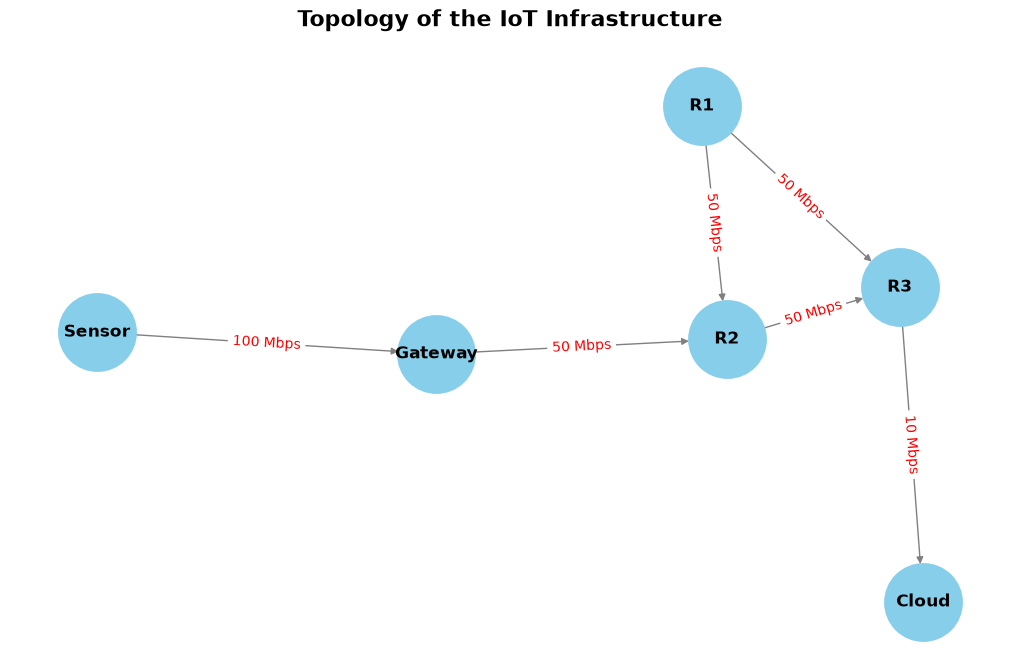

In [9]:
import networkx as nx
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

pos_base = nx.kamada_kawai_layout(infra)
pos = nx.spring_layout(infra, pos=pos_base, k=1.0, iterations=50, seed=42)

nx.draw(
    infra,
    pos,
    with_labels=True,
    node_color='skyblue',
    node_size=3000,
    font_size=12,
    font_weight='bold',
    edge_color='gray',
    linewidths=2
)

edge_labels = nx.get_edge_attributes(infra, 'bandwidth_mbps')
if edge_labels:
    formatted_labels = {edge: f"{bw} Mbps" for edge, bw in edge_labels.items()}
    nx.draw_networkx_edge_labels(infra, pos, edge_labels=formatted_labels, font_color='red')

plt.title("Topology of the IoT Infrastructure", fontsize=16, fontweight='bold', pad=20)
plt.axis('off')
plt.show()

In [10]:
import pandas as pd
import json
import os

json_path = f"{FAULT_RESULTS}/json/application.jsonl"
df_list = []

if not os.path.exists(json_path):
    raise FileNotFoundError(f"File {json_path} not found")

# Lecture of the JSONL file and filtering for routing metrics
with open(json_path, 'r') as file:
    for line in file:
        if line.strip():
            record = json.loads(line)
            
            # Filter using the callback_name to only include routing metrics
            if record.get("callback_name") == "traffic_routing":
                step_dict = {}
                metrics = [m for m in record.get("data", []) if len(m) == 3]
                
                # Reconstruct the original dictionary
                for app_id, col_name, val_list in metrics:
                    step_dict[col_name] = val_list
                
                # Convert to DataFrame in O(1) time if there are data
                if step_dict:
                    df_list.append(pd.DataFrame(step_dict))

if not df_list:
    raise ValueError("The JSONL file is empty or does not contain valid routing metrics.")

# Fusion of all steps into a single DataFrame
df_pivot = pd.concat(df_list, ignore_index=True)

# Rename columns to maintain compatibility with the old log names
df_pivot.rename(columns={
    'step': 'Step',
    'packet_id': 'Packet_ID',
    'hop_count': 'Hop_ID'
}, inplace=True)

# Conversion of types for safety
numeric_cols = ['arrival_at_next', 'processing_ms', 'queue_ms', 'transmission_ms', 'propagation_ms']
for col in numeric_cols:
    if col in df_pivot.columns:
        df_pivot[col] = pd.to_numeric(df_pivot[col], errors='coerce')

df_pivot['queue_length'] = pd.to_numeric(df_pivot.get('queue_length', 0)).fillna(0).astype(int)

# Secure handling of the 'dropped' field
if 'dropped' in df_pivot.columns:
    df_pivot['dropped'] = df_pivot['dropped'].fillna(False).astype(bool)
else:
    df_pivot['dropped'] = False

if 'hop' not in df_pivot.columns:
    df_pivot['hop'] = "Route N/A"

# Print of the chronological log of hops
print("\n--- Chronological Log of Hops ---")

df_log = df_pivot.sort_values('arrival_at_next').dropna(subset=['arrival_at_next'])

for _, row in df_log.iterrows():
    route_name = str(row['hop'])
    drop_alert = " ⚠️ [DROPPED]" if row['dropped'] else ""

    print(f"[Arrival: {row['arrival_at_next']:7.4f} ms] | "
          f"Step: {row['Step']:<3} | "
          f"Pkt: {row['Packet_ID']:<3} (Hop {row['Hop_ID']}) | "
          f"Route: {route_name:<15} | "
          f"Queue: {row['queue_length']:>2} pkt | "
          f"Delay Queue: {row['queue_ms']:6.4f} ms{drop_alert}")


--- Chronological Log of Hops ---
[Arrival:  0.7250 ms] | Step: 1   | Pkt: 1   (Hop 1) | Route: Sensor->Gateway | Queue:  0 pkt | Delay Queue: 0.0000 ms
[Arrival:  0.8450 ms] | Step: 1   | Pkt: 2   (Hop 1) | Route: Sensor->Gateway | Queue:  1 pkt | Delay Queue: 0.1200 ms
[Arrival:  0.9650 ms] | Step: 1   | Pkt: 3   (Hop 1) | Route: Sensor->Gateway | Queue:  2 pkt | Delay Queue: 0.2400 ms
[Arrival:  1.0850 ms] | Step: 1   | Pkt: 4   (Hop 1) | Route: Sensor->Gateway | Queue:  3 pkt | Delay Queue: 0.3600 ms
[Arrival:  1.2250 ms] | Step: 2   | Pkt: 5   (Hop 1) | Route: Sensor->Gateway | Queue:  0 pkt | Delay Queue: 0.0000 ms
[Arrival:  1.2450 ms] | Step: 2   | Pkt: 1   (Hop 2) | Route: Gateway->R1     | Queue:  0 pkt | Delay Queue: 0.0000 ms
[Arrival:  1.3650 ms] | Step: 2   | Pkt: 2   (Hop 2) | Route: Gateway->R1     | Queue:  1 pkt | Delay Queue: 0.1200 ms
[Arrival:  1.4850 ms] | Step: 2   | Pkt: 3   (Hop 2) | Route: Gateway->R1     | Queue:  2 pkt | Delay Queue: 0.2400 ms
[Arrival:  1.